# How to griddify shapes

Engridden?

Basic example of making grid from geojson.

## Code setup

In [1]:
import os
from dataclasses import dataclass
import warnings

import geopandas as gpd
import matplotlib.pyplot as plt

# Add path to package:
import sys
sys.path.insert(0,'../')
import isopods.grid
import isopods.stick
import isopods.convert

In [2]:
@dataclass(frozen=True)
class Paths:
    '''Singleton object for storing paths to data and database.'''

    dir_data: str = '../data'
    lsoa_filename: str = 'lsoa2011_devon.geojson'

paths = Paths()

## Create grid

Make sure the GeoDataFrame index is the label for each region.

In [3]:
p = os.path.join(paths.dir_data, paths.lsoa_filename)
gdf = gpd.read_file(p).set_index('LSOA11CD')
gdf['geometry'] = gdf.make_valid()
# Check the coordinate reference system (CRS):
print(f'{gdf.crs.name} EPSG:{gdf.crs.to_epsg()}')

OSGB36 / British National Grid EPSG:27700


Set up grid:

In [4]:
bbox_shapes = gdf.total_bounds
cell_width = 5000  # metres for British National Grid
cell_height = 5000  # metres for British National Grid

bbox_grid = isopods.grid.make_grid_bounds_containing_bbox(
    bbox_shapes, cell_width, cell_height)
transform_dict = isopods.grid.make_transform_dict(
    bbox_grid, cell_width, cell_height)

# Check that grid setup is sensible:
print(bbox_shapes)  # xmin, ymin, xmax, ymax
display(transform_dict)

[212711.6182  34957.4029 337605.812  151204.9973]


{'xmin': np.float64(210000.0),
 'ymax': np.float64(155000.0),
 'cell_width': 5000,
 'cell_height': 5000,
 'n_cols': 26,
 'n_rows': 25,
 'xmax': np.float64(340000.0),
 'ymin': np.float64(30000.0)}

Stick shapes to grid:

In [5]:
df_props = isopods.stick.stick_shapes_to_grid(
    gdf, **transform_dict, print_progress=True)
# Remove cells that are under 50% full:
df_props = df_props[df_props['prop_cell_covered'] >= 0.5]

# Check the cells with overlapping polygons.
# Should see that prop_cell_covered is always less than 1.001.
m = df_props['prop_cell_covered'] >= 1.001
if len(df_props[m]) > 0:
    warnings.warn('Check the overlapping polygons.', UserWarning)
else:
    pass

100.0% of cells checked

/home/anna/geography/isopods/02_howto/../isopods/stick.py:107: UserWarning: Overlapping polygons present in 4 cells: overlap area will be counted twice.
  warnings.warn((


Convert to array:

In [6]:
# Convert to grid containing this data:
dict_labels_to_data = dict(zip(gdf.index, range(len(gdf))))

# Option 1:
# make grid of region labels then convert to required data.
arr_labels = isopods.convert.convert_df_to_2darray(
    df_props, 'label_majority', **transform_dict)
arr_values = isopods.convert.convert_grid_values(
    arr_labels, dict_labels_to_data)
# Option 2:
# make grid of required data directly.
df_props['values'] = df_props['label_majority'].map(dict_labels_to_data)
arr_values_2 = isopods.convert.convert_df_to_2darray(
    df_props, 'values', **transform_dict)
# Check equivalence of options 1 and 2:
print((arr_values == arr_values_2).all())

True


Plot the grid:

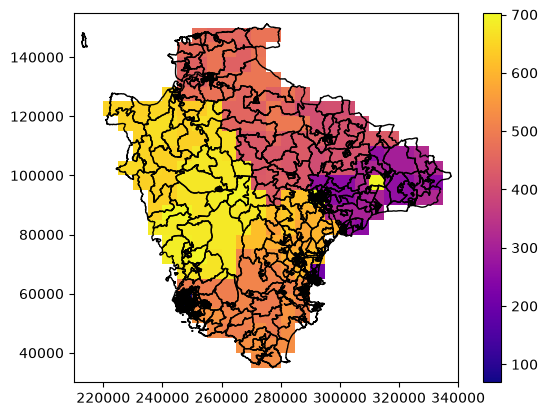

In [7]:
# For plotting the grid with imshow:
extent = (transform_dict['xmin'], transform_dict['xmax'],
          transform_dict['ymin'], transform_dict['ymax'])

fig, ax = plt.subplots()
cmap = plt.get_cmap('plasma')
# cmap.set_bad(color='LimeGreen')  # colour of invalid cells.
cl = ax.imshow(arr_values, origin='lower', extent=extent, cmap=cmap)
plt.colorbar(cl)
# Overlay shapes:
gdf.plot(ax=ax, facecolor='None', edgecolor='k')
plt.show()